In [1]:
# Check python version
#@title Imports (RUN ME!) { display-mode: "form" }
import sys,os
sys.version

import tensorflow as tf
from tensorflow import keras
#from keras.layers import Input

from tensorflow.keras import regularizers
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation, GlobalAveragePooling2D, Activation, Input

from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.callbacks import  EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import SGD


from keras.utils import to_categorical
from keras.utils import plot_model

#import imgaug as ia
#ia.seed(1)

%matplotlib inline
#from imgaug.augmentables.bbs import BoundingBox, BoundingBoxesOnImage
#from imgaug import augmenters as iaa 

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

import random
import imageio
import re
import shutil
from PIL import Image
import PIL.Image
PIL.Image.MAX_IMAGE_PIXELS = 969791964129 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cv2

import math

In [2]:
print("cv2", cv2.__version__)
print("pandas", pd.__version__)
print("PIL", Image.__version__)

cv2 4.11.0
pandas 2.3.3
PIL 11.3.0


In [3]:
import sys
import skimage
import sklearn
import keras
print('Python       :', sys.version.split('\n')[0])
print('Numpy        :', np.__version__)
print('Skimage      :', skimage.__version__)
print('Scikit-learn :', sklearn.__version__)
print('Keras        :', keras.__version__)
print('Tensorflow   :', tf.__version__)

Python       : 3.11.13 (main, Jun  5 2025, 08:21:08) [Clang 14.0.6 ]
Numpy        : 2.0.2
Skimage      : 0.26.0
Scikit-learn : 1.6.1
Keras        : 3.12.1
Tensorflow   : 2.21.0


In [4]:
#!pip install imgaug

In [5]:
#update imagegenerator function
#!pip uninstall keras-preprocessing -y
#!pip install git+https://github.com/keras-team/keras-preprocessing.git
from keras_preprocessing.image import ImageDataGenerator
#=rom keras.preprocessing.image import ImageDataGenerator


In [6]:
#!pip install keras-preprocessing

In [7]:
root_dir = "/Users/triscillar/Documents/Professional development/Journal Submissions/data MDPI/Wildlife Fences Dataset 2/Still_Images/Localization/Images/"
os.listdir(root_dir)

['annotation_localisation.csv',
 'annotation_localisation.xlsx',
 '.DS_Store',
 'double_fence',
 'single_fence']

In [8]:
path = os.path.join(root_dir)

# EDA

In [9]:
# view files
for f in os.listdir(path):
    print(f)

annotation_localisation.csv
annotation_localisation.xlsx
.DS_Store
double_fence
single_fence


In [10]:
labels_df = pd.read_csv(root_dir +"annotation_localisation.csv")
labels_df

,filename,width,height,class,xmin,ymin,xmax,ymax
0,Rhodes-University-Location-1-Image-Data%20(10)...,512,512,single_fence,55.003429,0.000000,512.000000,512.000000
1,Rhodes-University-Location-1-Image-Data%20(11)...,512,512,single_fence,81.920000,0.000000,512.000000,512.000000
2,Rhodes-University-Location-1-Image-Data%20(12)...,512,512,single_fence,138.678857,0.000000,512.000000,512.000000
3,Rhodes-University-Location-1-Image-Data%20(1).png,512,512,single_fence,0.000000,0.000000,318.317714,512.000000
4,Rhodes-University-Location-1-Image-Data%20(13)...,512,512,single_fence,119.369143,0.000000,512.000000,512.000000
...,...,...,...,...,...,...,...,...
153,Rhodes-University-Location-2-Image-Data%20(77)...,512,512,double_fence,0.000000,93.037714,512.000000,378.587429
154,Rhodes-University-Location-2-Image-Data%20(8).png,512,512,double_fence,0.585143,165.010286,512.000000,411.355429
155,Rhodes-University-Location-2-Image-Data%20(79)...,512,512,double_fence,0.585143,19.309714,512.000000,380.342857
156,Rhodes-University-Location-2-Image-Data%20(78)...,512,512,double_fence,0.585143,135.753143,512.000000,374.491429


In [11]:
labels_df.isnull().sum()

filename    0
width       0
height      0
class       0
xmin        0
ymin        0
xmax        0
ymax        0
dtype: int64

# Preprocess the dataset

In [12]:
classes_list = ['single_fence','double_fence']

In [13]:
image_folder = root_dir 

In [14]:
image_folder

'/Users/triscillar/Documents/Professional development/Journal Submissions/data MDPI/Wildlife Fences Dataset 2/Still_Images/Localization/Images/'

In [15]:
def preprocess_dataset(image_folder, classes_list, df, image_size = 300,):
    # Lists that will contain the whole dataset
    labels = []
    boxes = []
    img_list = []
    
    # Get height and width of each image in the datafame
    h = df['height']
    w = df['width']
    
    # Create a copy of the labels in the dataframe
    labels = list(df['class'])
    
    # Create a copy of the bounding box values and also normalize them 
    for x1, y1, x2, y2 in zip(list(df['xmin']/w), list(df['ymin']/h),list(df['xmax']/w), list(df['ymax']/h)):
        arr = [x1, y1, x2, y2]
        boxes.append(arr)
        
    # We loop over each class and its labels 
    for class_folder in classes_list:  
        
        # Set our images directory
        image_dir = os.path.join(image_folder, class_folder)
        
        # Annotation and Image files
        img_files = sorted(os.listdir(image_dir))
        
        
        # Loop over each of the image and its label
        for image_file in img_files:
            
            # Full path Image
            img_path = os.path.join(image_dir, image_file)
            
            # Read the image
            img  = cv2.imread(img_path)

            if img is None:
                print("Could not read image:", img_path)
                continue
                
            image = cv2.resize(img, (image_size, image_size))
            image = image.astype("float32") / 255.0
            
            #if img is None:
              #  print('Wrong path:', path)
            #else:
                # Resize all images to a fix size
                #image = cv2.resize(img, (image_size, image_size))
                
            # Normalize the image by dividing it by 255.0 
            #image = image.astype("float") / 255.0
            
            # Append it to the list of images
            img_list.append(image)

    return labels, boxes, img_list

In [16]:
# All images will resized to 300, 300 
image_size = 300

# Get images and bounding boxes
labels, boxes, img_list = preprocess_dataset(image_folder, classes_list, labels_df)
    

Could not read image: /Users/triscillar/Documents/Professional development/Journal Submissions/data MDPI/Wildlife Fences Dataset 2/Still_Images/Localization/Images/single_fence/.DS_Store


We'll Shuffle the data after preprocessing is done.



In [17]:
# Convert labels to integers, then one hot encode them
label_encoder = LabelEncoder()
integer_labels = label_encoder.fit_transform(labels)
onehot_labels = to_categorical(integer_labels)

# Now we need to shuffle the data, so zip all lists and shuffle
combined_list = list(zip(img_list, boxes, onehot_labels))
random.shuffle(combined_list)

# Extract back the contents of each list
img_list, boxes, onehot_labels = zip(*combined_list)

print('All Done')

All Done


## **Visualize the Data with its Annotations**
Here we will pick some random images from each class and draw its associated bounding boxes over it. This way you’ll be able to visualize the data and make sure that your preprocessing steps were done correctly.

In [18]:
# Create a Matplotlib figure
plt.figure(figsize=(20,20));

# Generate a random sample of images each time the cell is run 
random_range = random.sample(range(1, len(img_list)), 20)

for iteration, i in enumerate(random_range, 1):

    # Bounding box of each image
    a1, b1, a2, b2 = boxes[i];

    # Rescaling the boundig box values to match the image size
    x1 = a1 * image_size
    x2 = a2 * image_size
    y1 = b1 * image_size
    y2 = b2 * image_size

    # The image to visualize
    image = img_list[i]

    # Draw bounding boxes on the image
    cv2.rectangle(image, (int(x1),int(y1)),
          (int(x2),int(y2)),
                  (0,255,0),
                  3);
    
    # Clip the values to 0-1 and draw the sample of images
    image = np.clip(img_list[i], 0, 1)
    plt.subplot(4, 5, iteration);
    plt.imshow(image);
    plt.axis('off');

## **Split the Data into Train and Validation Set**
Now we would have 3 lists, one list containing all images, the second one contains all class labels in one hot encoded format and the third one list contains scaled bounding box coordinates. Let’s split our data to create a training and validation set. It’s important that you shuffle your data before the split which we have already done.


In [19]:
# Split the data of images, labels and their annotations
train_images, val_images, train_labels, \
val_labels, train_boxes, val_boxes = train_test_split( np.array(img_list), 
                np.array(onehot_labels), np.array(boxes), test_size = 0.1, 
                random_state = 43)

print('Total Training Images: {}, Total Validation Images: {}'.format(
    len(train_images), len(val_images) ))

Total Training Images: 142, Total Validation Images: 16


## **Construct the Multi Output Model**
Now it’s time to create our Multi Output model. We won’t be training from scratch but we will use transfer learning. The model we’ll use is NasnetMobile. This is a really efficient model with a good balance of speed and accuracy,  It was created through Neural Architecture Research (NAS) which is an emerging field of AutoML.

We’ll first download the model but exclude the top, since we’ll be adding our own custom top


# Let's create a function that will construct our model
def create_model(no_of_classes):
    
    input_layer = Input(shape = (300,300,3))#Input(shape=(len(train_images),))

    
    # Create our Classification Head, final layer contains 
    # Ouput units = no. classes
    class_prediction = Dense(256, activation="relu")(input_layer)
    class_prediction = Dense(128, activation="relu")(class_prediction )
    class_prediction = Dropout(0.2)(class_prediction)
    class_prediction = Dense(64, activation="relu")(class_prediction)
    class_prediction = Dropout(0.2)(class_prediction )
    class_prediction = Dense(32, activation="relu")(class_prediction)
    class_prediction = Dense(no_of_classes, activation='softmax',
                             name="class_output")(class_prediction)

    # Create Our Localization Head, final layer contains 4 nodes for x1,y1,x2,y2
    # Respectively.
    box_output = Dense(256, activation="relu")(input_layer)
    box_output = Dense(128, activation="relu")(box_output)
    box_output = Dropout(0.2)(box_output )

    box_output = Dense(64, activation="relu")(box_output)
    box_output = Dropout(0.2)(box_output )

    box_output = Dense(32, activation="relu")(box_output)
    box_predictions = Dense(4, activation='sigmoid',
                            name= "box_output")(box_output)

    # Now combine the two heads
    model = keras.Model(inputs=input_layer, outputs= [box_predictions, 
                                                   class_prediction])

    return model


model = create_model(2); print("Model Created")

In [20]:
# Load the NasNetMobile Model, make sure to exclude the top for transfer learning
N_mobile = tf.keras.applications.NASNetMobile( input_tensor = Input(
    shape=(image_size, image_size, 3)), 
    include_top=False, 
    weights='imagenet')

In [21]:
# Let's create a function that will construct our model
def create_model(no_of_classes):

    # Freeze the whole model
    N_mobile.trainable = False
    
    # Start by taking the output feature maps from NASNETMobile
    base_model_output = N_mobile.output
    
    # Convert to a single-dimensional vector by Global Average Pooling.

    # We could also use Flatten()(x) but GAP is more effective, it reduces 
    # Parameters and controls overfitting.
    flattened_output = GlobalAveragePooling2D()(base_model_output)

    # Create our Classification Head, final layer contains 
    # Ouput units = no. classes
    class_prediction = Dense(256, activation="relu")(flattened_output)
    class_prediction = Dense(128, activation="relu")(class_prediction )
    class_prediction = Dropout(0.2)(class_prediction)
    class_prediction = Dense(64, activation="relu")(class_prediction)
    class_prediction = Dropout(0.2)(class_prediction )
    class_prediction = Dense(32, activation="relu")(class_prediction)
    class_prediction = Dense(no_of_classes, activation='softmax',
                             name="class_output")(class_prediction)

    # Create Our Localization Head, final layer contains 4 nodes for x1,y1,x2,y2
    # Respectively.
    box_output = Dense(256, activation="relu")(flattened_output)
    box_output = Dense(128, activation="relu")(box_output)
    box_output = Dropout(0.2)(box_output )

    box_output = Dense(64, activation="relu")(box_output)
    box_output = Dropout(0.2)(box_output )

    box_output = Dense(32, activation="relu")(box_output)
    box_predictions = Dense(4, activation='sigmoid',
                            name= "box_output")(box_output)

    # Now combine the two heads
    model = keras.Model(inputs=N_mobile.input, outputs= [box_predictions, 
                                                   class_prediction])

    return model

# Create the model for 3 classes, Elephant, Butterfly, Cougar-Face
model = create_model(2); print("Model Created")

Model Created


p#lot_model(model, to_file='model_plot.png', show_shapes=True, 
           show_layer_names=True)

## **Compile & Train the Model**


Now here are a couple of things that you need to do. If this was a single output model you would have just defined a loss, a metric and an optimizer and compiled the model. Since we’re dealing with a multi output model that outputs two totally different things so we need to use seperate loss and separate metrics for both of these output branches.

Remember when we were creating the model we actually assigned names to our two output branches by doing that now we can easily refer to the name of an output branch and then assign it a specific loss or metric, just like a python dictionary. 


In [22]:
# Here for each head we will define a different loss, we will define it 
# Like a dictionary.

# For classification we will have cateogirical crossentropy
# For the bouding boxes we will have mean squared error
losses = { 
    "box_output": "mean_squared_error",
    "class_output": "categorical_crossentropy"
    }

# Here you can give more or less weightage to each loss. 

# If you think that detection is harder then the classification then you can 
# Try assinging it more weight
loss_weights = {
    "box_output": 1.0, 
    "class_output": 1.0
    }

# Set the Metrics
# For the class labels we want to know the Accuracy
# And for the bounding boxes we need to know the Mean squared error
metrics = {
    'class_output': 'accuracy', 
    'box_output':  'mse'
    }

# We will be using early stopping to stop the model if total val loss does not
# Decrease by 0.001 in 40 epochs
stop = EarlyStopping(monitor = "val_loss", min_delta = 0.0001, patience = 40, 
                    restore_best_weights = True
                     )

# Change the learning rate according to number of epochs to boost learning
reduce_lr = ReduceLROnPlateau(monitor = "val_loss", factor = 0.0002, 
                              patience = 30, min_lr = 1e-7, verbose = 1)

# Initialize Optimizer
opt = SGD( learning_rate = 1e-3, momentum = 0.9)

# Compile the model with Adam optimizer
model.compile(optimizer = opt, loss = losses, loss_weights = loss_weights, 
    metrics = metrics)

### **Start Training:**
When you're dealing with a multi output model then you need to assingn individual branches labels seperately like a dictionary. 

In [23]:
# Train the Model
history = model.fit(x = train_images, 
                    y= {
                        "box_output": train_boxes, 
                        "class_output": train_labels
                        }, 
                    validation_data=(
                        val_images, 
                        {
                          "box_output": val_boxes, 
                          "class_output": val_labels
                          }), batch_size = 32, epochs = 500, 
                    callbacks=[reduce_lr, stop])

Epoch 1/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - box_output_loss: 0.2064 - box_output_mse: 0.2070 - class_output_accuracy: 0.5141 - class_output_loss: 0.7207 - loss: 0.9363 - val_box_output_loss: 0.2036 - val_box_output_mse: 0.2036 - val_class_output_accuracy: 0.5625 - val_class_output_loss: 0.6896 - val_loss: 0.8932 - learning_rate: 0.0010
Epoch 2/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 511ms/step - box_output_loss: 0.2016 - box_output_mse: 0.2026 - class_output_accuracy: 0.5282 - class_output_loss: 0.6985 - loss: 0.9025 - val_box_output_loss: 0.1997 - val_box_output_mse: 0.1997 - val_class_output_accuracy: 0.6250 - val_class_output_loss: 0.6828 - val_loss: 0.8825 - learning_rate: 0.0010
Epoch 3/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 520ms/step - box_output_loss: 0.1959 - box_output_mse: 0.1964 - class_output_accuracy: 0.4859 - class_output_loss: 0.6835 - loss: 0.8883 - val_box_output_loss: 0.1947 - val_box_output_mse: 0.1947 - val_class_output_accuracy: 0.6250 - val_class_output_loss: 0.6772 - va

6/6 [==============================] - 5s 923ms/step - loss: 0.2732 - box_output_loss: 0.0284 - class_output_loss: 0.2448 - box_output_mse: 0.0284 - class_output_accuracy: 0.9206 - val_loss: 0.9428 - val_box_output_loss: 0.0229 - val_class_output_loss: 0.9199 - val_box_output_mse: 0.0229 - val_class_output_accuracy: 0.6667
Epoch 50/500
6/6 [==============================] - 5s 904ms/step - loss: 0.2781 - box_output_loss: 0.0279 - class_output_loss: 0.2503 - box_output_mse: 0.0279 - class_output_accuracy: 0.9153 - val_loss: 0.8976 - val_box_output_loss: 0.0228 - val_class_output_loss: 0.8748 - val_box_output_mse: 0.0228 - val_class_output_accuracy: 0.6190
Epoch 51/500
6/6 [==============================] - 5s 922ms/step - loss: 0.2695 - box_output_loss: 0.0285 - class_output_loss: 0.2409 - box_output_mse: 0.0285 - class_output_accuracy: 0.9312 - val_loss: 0.8943 - val_box_output_loss: 0.0228 - val_class_output_loss: 0.8715 - val_box_output_mse: 0.0228 - val_class_output_accuracy: 0.6190

## **Plot Model’s Loss & Accuracy Curves**
Now we had seperate losses and sperate metrics for differnt branches, on top of that we used a validation set. We're now dealing with 10 total metrics. Let's visualize and understand these by plotting them.

In [24]:
def plot(var1, var2, plot_name):
    # Get the loss metrics from the trained model
    c1 = history.history[var1]
    c2 = history.history[var2]
    
    epochs = range(len(c1))
    
    # Plot the metrics
    plt.plot(epochs, c1, 'b', label=var1)
    plt.plot(epochs, c2, 'r', label=var2)
    plt.title(str(plot_name))
    plt.legend()

In [25]:
plot('class_output_accuracy','val_class_output_accuracy','Class Output Accuracy vs Class Validation Accuracy')

In [26]:
plot('class_output_loss','val_class_output_loss','Class Output Loss vs Class Validation Loss')

In [27]:
plot('box_output_mse','val_box_output_mse','Box Output MSE vs Box Validation MSE')

In [28]:
plot('box_output_loss','val_box_output_loss','Box Output Loss vs Box Validation Loss')

In [29]:
# These are the most important metrics in telling us how our model is doing
plot('loss','val_loss',' Total Loss vs Total Validation Loss')

### **Save Your Model**
You should save your model for future runs.

In [30]:
# Save the entire model as a `.keras` zip archive.
model.save('my_model_localize_still.keras')

In [31]:

# Load the saved model
new_model = tf.keras.models.load_model('my_model_localize_still.keras')

## **Test your model on New Images**
In this step we will create a function that will use the model to predict on new images.

In [32]:
# Class names used during training
label_names = sorted(classes_list)
print("Class mapping:", {i: name for i, name in enumerate(label_names)})

# Predict on all validation images
predictions = new_model.predict(val_images, verbose=0)

# Extract model outputs
pred_boxes = predictions[0]   # box_output
pred_label_probs = predictions[1]  # class_output

# Ground-truth boxes and labels
true_boxes = np.asarray(val_boxes)
true_labels = np.asarray(val_labels)

# Convert predicted class probabilities to class indices
pred_class_indices = np.argmax(pred_label_probs, axis=1)

# Convert ground-truth one-hot labels to class indices
if true_labels.ndim > 1 and true_labels.shape[-1] > 1:
    true_class_indices = np.argmax(true_labels, axis=1)
else:
    true_class_indices = true_labels.reshape(-1).astype(int)

# Convert class indices to strings
pred_class_names = [str(label_names[i]) for i in pred_class_indices]
true_class_names = [str(label_names[i]) for i in true_class_indices]

Class mapping: {0: 'double_fence', 1: 'single_fence'}


In [33]:
def box_iou_dice(pred_box, true_box):
    px1, py1, px2, py2 = pred_box
    gx1, gy1, gx2, gy2 = true_box

    intersection = (
        max(0, min(px2, gx2) - max(px1, gx1))
        * max(0, min(py2, gy2) - max(py1, gy1))
    )

    pred_area = max(0, px2 - px1) * max(0, py2 - py1)
    true_area = max(0, gx2 - gx1) * max(0, gy2 - gy1)

    union = pred_area + true_area - intersection
    iou = intersection / union if union > 0 else 0.0

    denominator = pred_area + true_area
    dice = 2 * intersection / denominator if denominator > 0 else 0.0

    return iou, dice

In [34]:
# Store evaluation results and visualisations
results = []
visual_images = []

n = min(
    len(val_images),
    len(pred_boxes),
    len(true_boxes),
    len(pred_class_names),
    len(true_class_names)
)

for i in range(n):

    # Recover validation image (assumed RGB, scaled to [0, 1])
    img = np.asarray(val_images[i]).copy()

    if img.ndim == 4:
        img = img[0]

    if img.dtype != np.uint8:
        if img.max() <= 1.0:
            img = img * 255.0
        img = np.clip(img, 0, 255).astype(np.uint8)

    # Convert RGB to BGR for OpenCV
    visual = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    h, w = visual.shape[:2]

    # Extract boxes
    pred_box = np.asarray(pred_boxes[i]).reshape(-1)[:4].astype(float)
    true_box = np.asarray(true_boxes[i]).reshape(-1)[:4].astype(float)

    # Convert normalised coordinates to pixels.
    # This assumes both box arrays use the same coordinate format.
    if max(np.abs(pred_box).max(), np.abs(true_box).max()) <= 1.0:
        pred_box[[0, 2]] *= w
        pred_box[[1, 3]] *= h
        true_box[[0, 2]] *= w
        true_box[[1, 3]] *= h

    pred_box = np.rint(pred_box).astype(int)
    true_box = np.rint(true_box).astype(int)

    # Calculate bounding-box metrics
    iou, dice = box_iou_dice(pred_box, true_box)

    # Individual class labels as strings
    pred_label = pred_class_names[i]
    true_label = true_class_names[i]
    class_correct = pred_label == true_label

    # Draw ground-truth box in green
    gx1, gy1, gx2, gy2 = true_box
    cv2.rectangle(
        visual, (gx1, gy1), (gx2, gy2), (0, 255, 0), 1
    )

    # Draw predicted box in red
    px1, py1, px2, py2 = pred_box
    cv2.rectangle(
        visual, (px1, py1), (px2, py2), (0, 0, 255), 1
    )

    # Add predicted and true labels
    cv2.putText(
        visual, f"True: {true_label}",
        (10, 25), cv2.FONT_HERSHEY_SIMPLEX,
        0.55, (0, 255, 0), 1
    )
    cv2.putText(
        visual, f"Pred: {pred_label}",
        (10, 50), cv2.FONT_HERSHEY_SIMPLEX,
        0.55, (0, 0, 255), 1
    )
    cv2.putText(
        visual, f"IoU: {iou:.3f} Dice: {dice:.3f}",
        (10, 75), cv2.FONT_HERSHEY_SIMPLEX,
        0.55, (255, 255, 0), 1
    )

    results.append({
        "image_index": i,
        "true_label": true_label,
        "predicted_label": pred_label,
        "class_correct": class_correct,
        "IoU": iou,
        "Dice": dice,
        "pred_box": pred_box.tolist(),
        "true_box": true_box.tolist()
    })

    visual_images.append(cv2.cvtColor(visual, cv2.COLOR_BGR2RGB))


# Summarise results
df_val_results = pd.DataFrame(results)

print("Validation images evaluated:", len(df_val_results))

if not df_val_results.empty:
    print(f"Mean IoU: {df_val_results['IoU'].mean():.4f}")
    print(f"Mean bounding-box Dice: {df_val_results['Dice'].mean():.4f}")
    print(
        "Classification accuracy: "
        f"{df_val_results['class_correct'].mean():.4f}"
    )
    
# Mean Squared Error for bounding-box coordinates


    mse = np.mean((pred_box - true_box) ** 2)

    print(f"Bounding-box MSE: {mse:.4f}")
display(df_val_results)

# Save per-image results
df_val_results.to_csv("validation_iou_dice_results_still.csv", index=False)



Validation images evaluated: 16
Mean IoU: 0.5515
Mean bounding-box Dice: 0.6778
Classification accuracy: 0.8750
Bounding-box MSE: 661.2500


,image_index,true_label,predicted_label,class_correct,IoU,Dice,pred_box,true_box
0,0,single_fence,single_fence,True,0.422500,0.594025,"[41, 66, 266, 235]","[0, 0, 300, 300]"
1,1,single_fence,single_fence,True,1.000000,1.000000,"[0, 0, 1, 1]","[0, 0, 1, 1]"
2,2,single_fence,single_fence,True,0.668899,0.801605,"[24, 55, 279, 257]","[0, 16, 300, 243]"
3,3,single_fence,single_fence,True,0.359333,0.528690,"[43, 73, 251, 224]","[81, 0, 300, 300]"
4,4,double_fence,double_fence,True,0.246194,0.395113,"[80, 93, 231, 190]","[0, 110, 300, 265]"
5,5,double_fence,double_fence,True,0.688787,0.815718,"[33, 65, 268, 249]","[1, 76, 300, 232]"
6,6,double_fence,double_fence,True,0.443380,0.614363,"[43, 69, 266, 239]","[0, 124, 300, 213]"
7,7,double_fence,single_fence,False,0.404511,0.576017,"[41, 68, 259, 235]","[0, 0, 300, 300]"
8,8,double_fence,double_fence,True,0.480000,0.648649,"[30, 63, 270, 243]","[0, 0, 300, 300]"
9,9,double_fence,double_fence,True,0.197842,0.330330,"[101, 107, 211, 182]","[0, 80, 300, 219]"


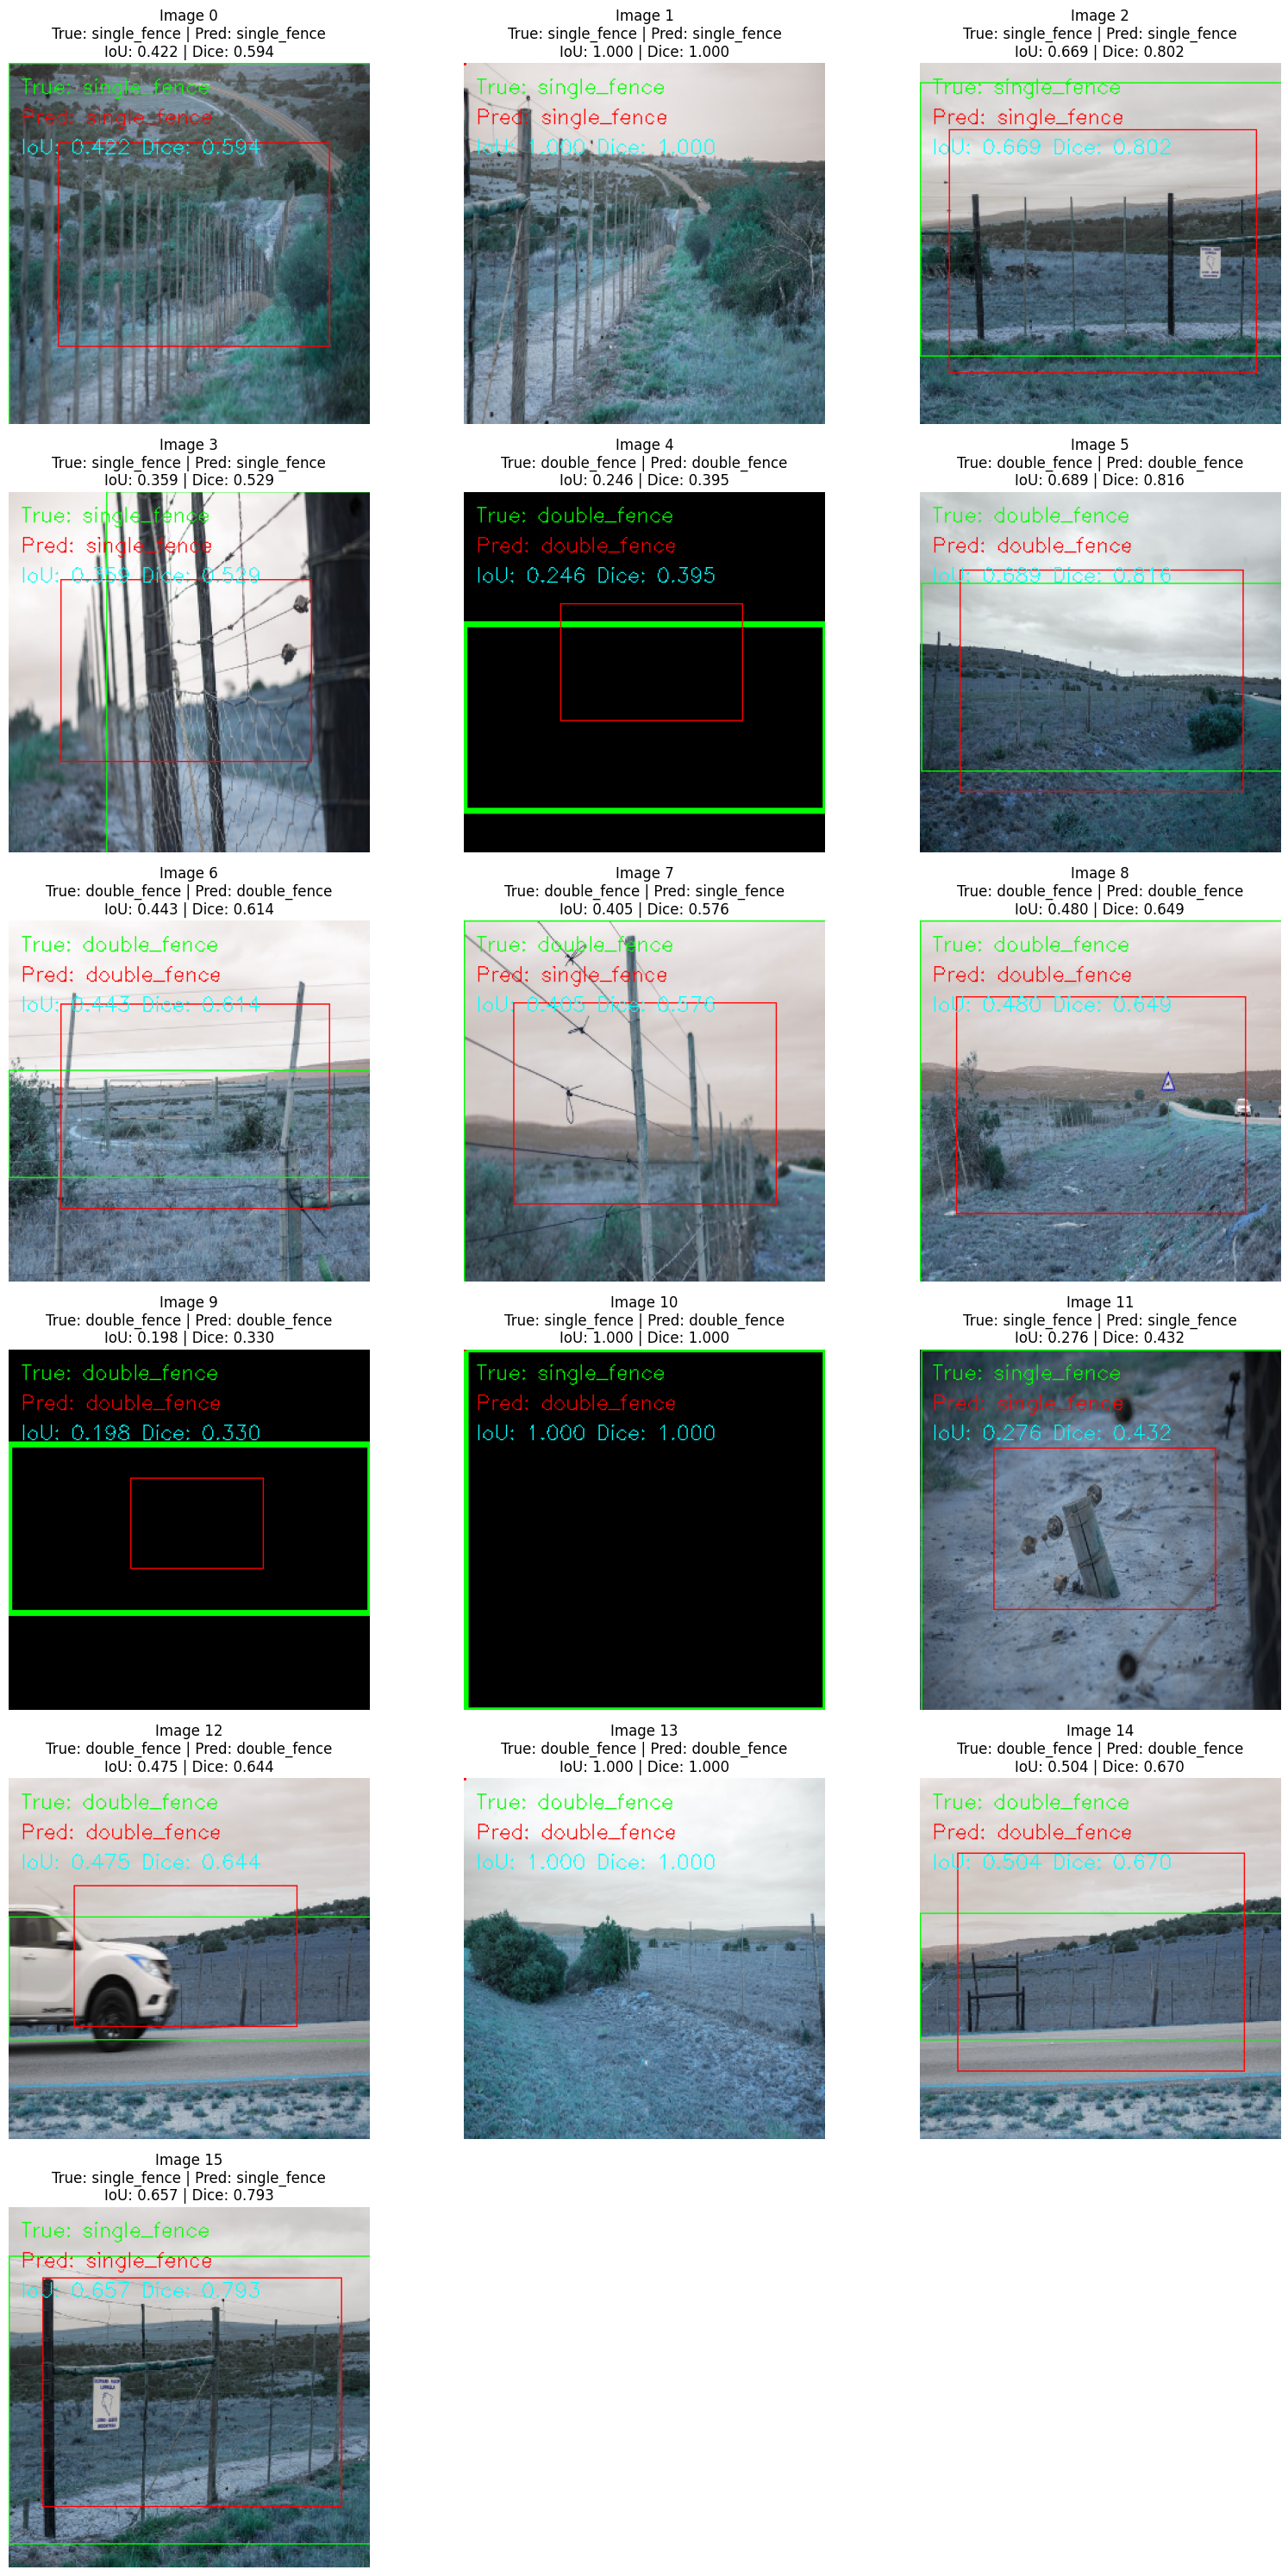

In [36]:

# Display validation images in a grid
if visual_images:
    cols = 3
    rows = math.ceil(len(visual_images) / cols)

    plt.figure(figsize=(16, 5 * rows))

    for i, img in enumerate(visual_images):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(
            f"Image {i}\n"
            f"True: {results[i]['true_label']} | "
            f"Pred: {results[i]['predicted_label']}\n"
            f"IoU: {results[i]['IoU']:.3f} | "
            f"Dice: {results[i]['Dice']:.3f}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()